In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Notebook is inside the notebooks/ folder
PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "data" / "processed" / "analysis"

trends = pd.read_csv(DATA / "international_trends.csv")
flows = pd.read_csv(DATA / "international_country_flows.csv")
balance = pd.read_csv(DATA / "country_balance.csv")

print("Annual trends:", trends.shape)
print("Country flows:", flows.shape)
print("Country balance:", balance.shape)

display(balance.head())


Annual trends: (10, 3)
Country flows: (10490, 4)
Country balance: (366, 5)


,YEAR,COUNTRY,incoming,outgoing,net_mobility
0,2014,AT,3887,3509,378
1,2014,BE,5483,4488,995
2,2014,BG,598,871,-273
3,2014,CH,2,0,2
4,2014,CY,483,219,264


In [2]:

overall = (
    balance.groupby("COUNTRY", as_index=False)
    [["incoming", "outgoing"]]
    .sum()
)

overall["net_mobility"] = (
    overall["incoming"] - overall["outgoing"]
)

overall["incoming_outgoing_ratio"] = (
    overall["incoming"] /
    overall["outgoing"].replace(0, float("nan"))
)

overall = overall.sort_values(
    "net_mobility", ascending=False
)

display(overall)


,COUNTRY,incoming,outgoing,net_mobility,incoming_outgoing_ratio
36,UK,183911,110445,73466,1.665182
32,SE,87388,37102,50286,2.355345
29,PT,123622,77095,46527,1.603502
11,ES,397720,353395,44325,1.125426
27,NO,61706,23063,38643,2.675541
16,IE,63817,31873,31944,2.002228
12,FI,69050,41375,27675,1.668882
28,PL,131078,107078,24000,1.224136
2,BE,96560,72742,23818,1.327431
25,MT,19371,2761,16610,7.015936


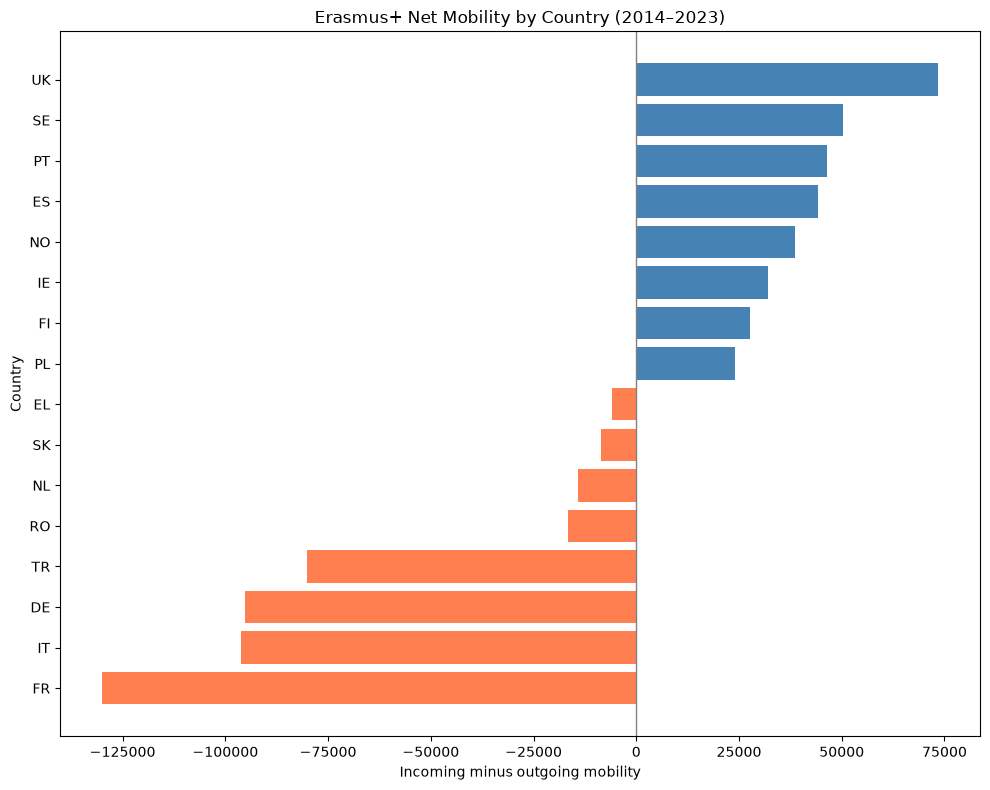

In [3]:

selected = pd.concat([
    overall.head(8),
    overall.tail(8)
]).sort_values("net_mobility")

fig, ax = plt.subplots(figsize=(10, 8))

colors = [
    "steelblue" if x >= 0 else "coral"
    for x in selected["net_mobility"]
]

ax.barh(
    selected["COUNTRY"],
    selected["net_mobility"],
    color=colors
)

ax.axvline(0, color="gray", linewidth=1)
ax.set_title("Erasmus+ Net Mobility by Country (2014–2023)")
ax.set_xlabel("Incoming minus outgoing mobility")
ax.set_ylabel("Country")

plt.tight_layout()
plt.show()
